# Project 1: Predicting Math Grades, and Knowing When Not to Trust the Prediction

Data: the UCI Student Performance data. The math course has 395 students and the Portuguese course has 649. Each student has 30 background and survey columns plus three grades on a 0 to 20 scale: G1, G2, and the final grade G3. The pass mark is 10. The goal is to predict the math final grade G3.

## Summary

With this dataset, most people would take G1, G2, and the survey columns, fit a regression or a random forest, and report one error number. That is fine, but it only answers "what grade will this student get", and I wanted to do something a little different. After looking at the data, two things stood out. First, the math grades have a pile of 38 students (9.6%) with a final grade of 0, and all 38 have 0 absences, while 25 of them had a G2 above 0. They look like students who dropped out or stopped showing up, not students who scored badly, and they are a small group that makes a very large error (a ridge model has an RMSE of 5.153 on them against 1.331 on everyone else). Second, there are only 395 math students but 649 Portuguese students, and many of the same students are in both courses. I also read arXiv papers that did cool things with grade data from other schools (not this dataset) and got three ideas form this that i wanted to explore: give each prediction a range instead of one number (conformal prediction, Morsomme and Smirnov), start a model for one course from what was learned in another (a prior, like Schwerter et al. did across cohorts), and split a prediction into separate jobs. So I chose to build a hurdle model for the zeros, a Portuguese prior for the math model, and conformal intervals on top of everything. The reason for running several models is that each one has a different job, and I compare them on more than error: how wide their ranges are, how many failing students they flag, and how they handle the zero students.

What I built: four models for math G3 using G1, G2, and the survey columns. Ridge (alpha picked by its built in CV from 0.1 to 1000), a random forest (300 trees, max_features 0.5, min_samples_leaf 2), a hurdle forest (one forest decides "is this student a zero", a second forest is trained only on the non zero students, and the prediction is (1 minus the zero probability) times the second forest's grade), and a ridge with a Portuguese prior (a ridge trained on the 275 Portuguese students who do not look like any math student, then a second ridge learns what is left over on the math students). Every model gets an 80% conformal interval (alpha 0.2) from a 60/20/20 train, calibration, test split, repeated over 30 random splits, and a student is flagged as "may fail" if the lower end of their interval is below 10. The prior is tested separately with G2 removed, using 20 to 300 math students and 30 repeats. In the results the forest and hurdle forest are tied on RMSE (1.679 and 1.690) and both beat ridge (2.081), the intervals cover about 81% to 83% of students, and the Portuguese prior helps a lot when there is little data (RMSE 3.009 vs 3.868 at 20 students) but the gain is almost gone by 300 students (2.727 vs 2.761). What I would change: the hurdle did not clearly beat the plain forest, so I would try tuning the zero classifier (it ranks zero students well, AUC 0.99, but gives real zeros only a 0.607 average probability, and a hard 0.5 cutoff was worse, 1.964); the intervals are the same width for every student, so they cannot say "I am less sure about this one", and I would try a conformal method whose width changes per student; and the zero students are badly covered (only 27.5% to 38.8% fall inside their interval), so a version that calibrates the zero group separately would be worth a try once there is more data. The zero students are only about 8 per calibration set, which is why I did not try that here.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore', category=UserWarning)

## Setup and a first look

Both files are read as is (semicolon separated). Before modelling I want to check how many zero grades there are in each course and what the zero students look like.

In [ ]:
math = pd.read_csv('student-mat.csv', sep=';')
port = pd.read_csv('student-por.csv', sep=';')

print('math rows:', len(math), ' portuguese rows:', len(port))
print('math students with G3 = 0:', (math['G3'] == 0).sum(), f"({(math['G3'] == 0).mean():.1%})")
print('portuguese students with G3 = 0:', (port['G3'] == 0).sum(), f"({(port['G3'] == 0).mean():.1%})")
print('math students with absences = 0:', (math['absences'] == 0).sum())
print('math students with G3 = 0 and absences = 0:', ((math['G3'] == 0) & (math['absences'] == 0)).sum())
print('math students with absences > 0 and G3 = 0:', ((math['G3'] == 0) & (math['absences'] > 0)).sum())
print('math students with G3 = 0 but G2 > 0:', ((math['G3'] == 0) & (math['G2'] > 0)).sum())

math rows: 395  portuguese rows: 649
math students with G3 = 0: 38 (9.6%)
portuguese students with G3 = 0: 15 (2.3%)
math students with absences = 0: 115
math students with G3 = 0 and absences = 0: 38
math students with absences > 0 and G3 = 0: 0
math students with G3 = 0 but G2 > 0: 25


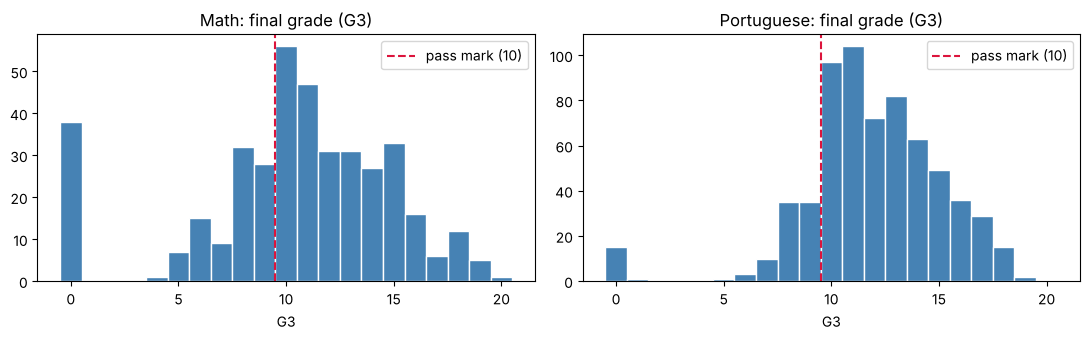

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=False)
for axis, data, name in [(axes[0], math, 'Math'), (axes[1], port, 'Portuguese')]:
    axis.hist(data['G3'], bins=np.arange(-0.5, 21.5, 1), color='steelblue', edgecolor='white')
    axis.axvline(9.5, color='crimson', linestyle='--', label='pass mark (10)')
    axis.set_title(f'{name}: final grade (G3)')
    axis.set_xlabel('G3')
    axis.legend()
plt.tight_layout()
plt.show()

Math has 38 students with a final grade of 0 (9.6%), against 15 in the Portuguese course (2.3%), and the histogram shows them sitting alone on the left, far from everyone else. All 38 have 0 absences, and no student with more than 0 absences has a G3 of 0. That does not mean 0 absences predicts a zero by itself, since 115 students have 0 absences and only 38 of them (a third) are zeros. 25 of the 38 had a G2 above 0, so they were still in the course for the second term and then ended at 0. My guess is that they dropped out or missed the final, but the data does not say, so that part is an inference.

### Which Portuguese students are safe to use for the prior?

The dataset comes with a merge script that says the same student can be found in both files by matching 13 background columns. I use that same key to find Portuguese students who look like a math student, and I leave them out of the prior. Otherwise the prior would already have seen some of the students it is later tested on, and it would look better than it is.

In [ ]:
match_columns = ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
                 'Mjob', 'Fjob', 'reason', 'nursery', 'internet']
math_keys = set(map(tuple, math[match_columns].values))
in_math = np.array([tuple(row) in math_keys for row in port[match_columns].values])

port_clean = port[~in_math].reset_index(drop=True)
print('portuguese students who also look like a math student:', in_math.sum())
print('portuguese students kept for the prior:', len(port_clean))
print('portuguese students kept with G3 = 0:', (port_clean['G3'] == 0).sum())

portuguese students who also look like a math student: 374
portuguese students kept for the prior: 275
portuguese students kept with G3 = 0: 10


374 of the 649 Portuguese students match a math student on the 13 columns, which leaves 275 for the prior (10 of them are zeros). The match is approximate (it is the same rule the dataset's own merge script uses, and two different students can share the same 13 values), so a few math students may still be in the 275, and a few real Portuguese only students may have been dropped.

## Helpers

make_features drops G3 (and optionally G2). make_preprocessor one hot encodes the text columns and scales the number columns, and it sits inside every pipeline so it is refit on the training rows only. The forest settings are fixed (300 trees, max_features 0.5, min_samples_leaf 2) and I did not tune them, since the point is to compare ideas and not to squeeze out the best forest.

In [ ]:
def make_features(data, use_G2=True):
    return data.drop(columns=['G3'] if use_G2 else ['G3', 'G2'])

def make_preprocessor(features):
    text_columns = features.select_dtypes(exclude='number').columns
    return ColumnTransformer([('text', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), text_columns)],
                             remainder=StandardScaler())

def make_ridge(features):
    return make_pipeline(make_preprocessor(features), RidgeCV(alphas=np.logspace(-1, 3, 9)))

def make_forest_regressor(features):
    return make_pipeline(make_preprocessor(features),
                         RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2, random_state=0, n_jobs=-1))

def make_forest_classifier(features):
    return make_pipeline(make_preprocessor(features),
                         RandomForestClassifier(n_estimators=300, max_features=0.5, min_samples_leaf=2, random_state=0, n_jobs=-1))

## The four models

Each one is a small class with fit and predict, so they can all go through the same split and conformal code.

- **RidgeModel**: plain ridge regression, the simple baseline.
- **ForestModel**: random forest regressor, the flexible one.
- **HurdleModel**: a forest classifier predicts the chance the student is a zero, a forest regressor trained only on the non zero students predicts the grade, and the final prediction is (1 minus the zero chance) times that grade. If the model is sure a student is a zero, the prediction goes to 0, and if it is not sure, it lands in between.
- **PriorRidgeModel**: the Portuguese ridge makes a first guess for each math student, then a second ridge is trained on the math students to fix what that guess gets wrong (the residual).

In [ ]:
class RidgeModel:
    def fit(self, features, grades):
        self.model = make_ridge(features).fit(features, grades)
        return self
    def predict(self, features):
        return self.model.predict(features)

class ForestModel:
    def fit(self, features, grades):
        self.model = make_forest_regressor(features).fit(features, grades)
        return self
    def predict(self, features):
        return self.model.predict(features)

class HurdleModel:
    def fit(self, features, grades):
        is_zero = (grades == 0).values
        self.zero_model = make_forest_classifier(features).fit(features, is_zero)
        self.grade_model = make_forest_regressor(features).fit(features[~is_zero], grades[~is_zero])
        return self
    def zero_probability(self, features):
        return self.zero_model.predict_proba(features)[:, 1]
    def predict(self, features):
        return (1 - self.zero_probability(features)) * self.grade_model.predict(features)

class PriorRidgeModel:
    def __init__(self, port_features, port_grades):
        self.prior = make_ridge(port_features).fit(port_features, port_grades)
    def fit(self, features, grades):
        self.residual_model = make_ridge(features).fit(features, grades - self.prior.predict(features))
        return self
    def predict(self, features):
        return self.prior.predict(features) + self.residual_model.predict(features)

## Part 1: Four models, each with a conformal interval

Conformal prediction here is the simple split version. I train on one part of the data, then on a separate calibration part I measure how far off each prediction is. The 80th percentile of those errors becomes a plus or minus range around every test prediction, and if the calibration students look like the test students, about 80% of real grades should land inside the range. I flag a student as "may fail" when the lower end of their range is below 10.

Because there are only about 79 test students per split, one split is very noisy, so I repeat the whole thing with 30 different random splits (stratified on zero vs not zero so each part has a similar number of zeros). The cell below also tracks how the hurdle's zero classifier behaves.

In [ ]:
alpha = 0.2
pass_mark = 10

def conformal_width(calibration_grades, calibration_predictions):
    scores = np.abs(calibration_grades - calibration_predictions)
    n = len(scores)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return np.quantile(scores, level, method='higher')

def split_math(seed):
    is_zero = math['G3'] == 0
    rest_index, test_index = train_test_split(math.index, test_size=0.2, stratify=is_zero, random_state=seed)
    train_index, calibration_index = train_test_split(rest_index, test_size=0.25, stratify=is_zero[rest_index], random_state=seed)
    return train_index, calibration_index, test_index

math_X = make_features(math)
port_X = make_features(port_clean)
model_names = ['Ridge', 'Forest', 'Hurdle forest', 'Ridge + Portuguese prior']

def run_one_split(seed):
    train_index, calibration_index, test_index = split_math(seed)
    models = {
        'Ridge': RidgeModel(),
        'Forest': ForestModel(),
        'Hurdle forest': HurdleModel(),
        'Ridge + Portuguese prior': PriorRidgeModel(port_X, port_clean['G3']),
    }
    rows, saved = [], {}
    test_grades = math.loc[test_index, 'G3']
    for name, model in models.items():
        model.fit(math_X.loc[train_index], math.loc[train_index, 'G3'])
        calibration_predictions = model.predict(math_X.loc[calibration_index])
        test_predictions = model.predict(math_X.loc[test_index])
        half_width = conformal_width(math.loc[calibration_index, 'G3'], calibration_predictions)
        lower, upper = test_predictions - half_width, test_predictions + half_width
        failing = test_grades < pass_mark
        not_zero = test_grades > 0
        covered = (test_grades >= lower) & (test_grades <= upper)
        rows.append({
            'seed': seed, 'model': name,
            'RMSE': np.sqrt(np.mean((test_grades - test_predictions) ** 2)),
            'RMSE without zeros': np.sqrt(np.mean((test_grades[not_zero] - test_predictions[not_zero]) ** 2)),
            'RMSE on zeros': np.sqrt(np.mean((test_grades[~not_zero] - test_predictions[~not_zero]) ** 2)),
            'MAE': np.mean(np.abs(test_grades - test_predictions)),
            'coverage': np.mean(covered),
            'coverage on zeros': np.mean(covered[~not_zero]),
            'interval width': 2 * half_width,
            'failing flagged': np.mean(lower[failing] < pass_mark),
            'passing flagged': np.mean(lower[~failing] < pass_mark),
        })
        saved[name] = (test_predictions, lower, upper)
    hurdle = models['Hurdle forest']
    zero_probability = hurdle.zero_probability(math_X.loc[test_index])
    hard_predictions = np.where(zero_probability > 0.5, 0, hurdle.grade_model.predict(math_X.loc[test_index]))
    is_real_zero = (test_grades == 0).values
    zero_stats = {
        'zero classifier AUC': roc_auc_score(is_real_zero, zero_probability),
        'mean probability, real zeros': zero_probability[is_real_zero].mean(),
        'mean probability, other students': zero_probability[~is_real_zero].mean(),
        'real zeros with probability above 0.5': (zero_probability[is_real_zero] > 0.5).mean(),
        'RMSE if the hurdle uses a hard 0.5 cutoff': np.sqrt(np.mean((test_grades - hard_predictions) ** 2)),
    }
    return rows, saved, test_index, zero_stats

all_rows, zero_stats_rows = [], []
for seed in range(30):
    rows, saved, test_index, zero_stats = run_one_split(seed)
    all_rows += rows
    zero_stats_rows.append(zero_stats)
    if seed == 0:
        first_saved, first_test_index = saved, test_index

results = pd.DataFrame(all_rows)
print(pd.DataFrame(zero_stats_rows).mean().round(3))
print('lowest zero classifier AUC in any split:', round(pd.DataFrame(zero_stats_rows)['zero classifier AUC'].min(), 3))

zero classifier AUC                          0.990
mean probability, real zeros                 0.607
mean probability, other students             0.036
real zeros with probability above 0.5        0.667
RMSE if the hurdle uses a hard 0.5 cutoff    1.964
dtype: float64
lowest zero classifier AUC in any split: 0.96


The zero classifier is very good at ranking students: the AUC is 0.990 on average and never lower than 0.96 in any split. But ranking is not the same as being sure. The real zero students get a 0.607 average zero probability and only 66.7% of them are above 0.5, while the other students average 0.036. So the model knows who is more likely to be a zero, but is rarely certain enough to push the prediction all the way to 0. When I force a hard cutoff (anything above 0.5 becomes 0) the RMSE goes up to 1.964, which is worse than the 1.690 of the soft version in the table below, so I kept the soft version.

### Results over 30 splits

How to read the columns (all averaged over the 30 splits): RMSE is the error on all test students, RMSE without zeros and RMSE on zeros split it into the two groups. Coverage is the share of test students whose real G3 falls inside their interval (the goal is 0.80), and coverage on zeros is the same for the zero students only. Interval width is the full width of the range in grade points. Failing flagged is the share of failing students (G3 below 10) whose lower end is below 10, so higher is better. Passing flagged is the same for passing students, which are the false alarms, so lower is better.

In [ ]:
summary = results.groupby('model').mean(numeric_only=True).drop(columns='seed').loc[model_names]
summary.round(3)

,RMSE,RMSE without zeros,RMSE on zeros,MAE,coverage,coverage on zeros,interval width,failing flagged,passing flagged
model,,,,,,,,,
Ridge,2.081,1.331,5.153,1.360,0.807,0.275,3.907,0.995,0.434
Forest,1.679,1.112,4.046,1.065,0.824,0.279,3.254,1.000,0.394
Hurdle forest,1.690,1.146,3.988,1.076,0.828,0.388,3.374,1.000,0.435
Ridge + Portuguese prior,1.999,1.140,5.250,1.241,0.808,0.308,3.320,0.997,0.409


In [ ]:
spread = results.groupby('model')[['RMSE', 'RMSE without zeros', 'RMSE on zeros', 'coverage', 'interval width']].std().loc[model_names]
spread.round(3)

,RMSE,RMSE without zeros,RMSE on zeros,coverage,interval width
model,,,,,
Ridge,0.198,0.194,0.751,0.056,0.584
Forest,0.225,0.179,0.861,0.049,0.403
Hurdle forest,0.231,0.185,0.934,0.051,0.405
Ridge + Portuguese prior,0.219,0.143,0.816,0.054,0.391


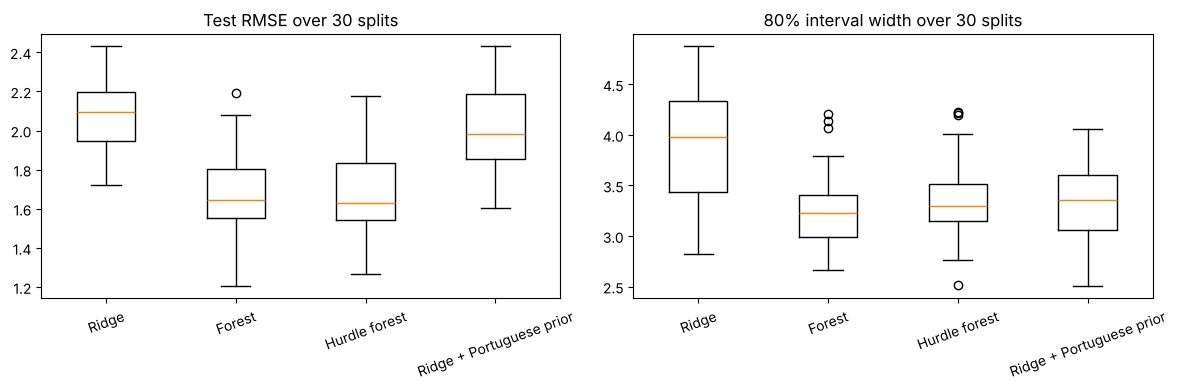

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot([results.loc[results['model'] == name, 'RMSE'] for name in model_names], tick_labels=model_names)
axes[0].set_title('Test RMSE over 30 splits')
axes[0].tick_params(axis='x', rotation=20)
axes[1].boxplot([results.loc[results['model'] == name, 'interval width'] for name in model_names], tick_labels=model_names)
axes[1].set_title('80% interval width over 30 splits')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

The forest and the hurdle forest are tied: RMSE 1.679 vs 1.690, and in the boxplot their boxes overlap almost completely, while ridge (2.081) sits clearly higher. The error is mostly the zero students: ridge is off by 5.153 on them against 1.331 on the others, and the forest is at 4.046 against 1.112. The hurdle is slightly better on the zero students (3.988) but slightly worse on everyone else (1.146 vs 1.112), and the two cancel out, so on this data the plain forest already does about as well as the special zero model. The Portuguese prior helps ridge a bit when all the grades are available (RMSE 1.999 vs 2.081, and 1.140 vs 1.331 without the zeros), but not on the zero students (5.250 vs 5.153), which makes sense because the Portuguese course has very few zeros to learn from.

The intervals do what they promise on average: coverage is 0.807 to 0.828 for a goal of 0.80. The forest has the narrowest ranges (3.254 grade points wide) and ridge has the widest (3.907), and ridge's width also changes the most between splits (standard deviation 0.584 vs about 0.4 for the others), so the better the model, the tighter the range for the same 80%. Every model flags almost every failing student (0.995 to 1.000), but also flags 39% to 44% of the passing students, so the flag is good at not missing students and bad at not raising false alarms. The forest has the fewest false alarms (0.394) and the hurdle the most (0.435).

The average hides one problem: coverage on the zero students is only 0.275 for ridge, 0.279 for the forest, 0.308 for the prior ridge, and 0.388 for the hurdle. The hurdle is the best at covering the zero students, which is the one place it helps, but it is still far from 0.80, since the interval has the same width for every student and the zero students are far from their predictions.

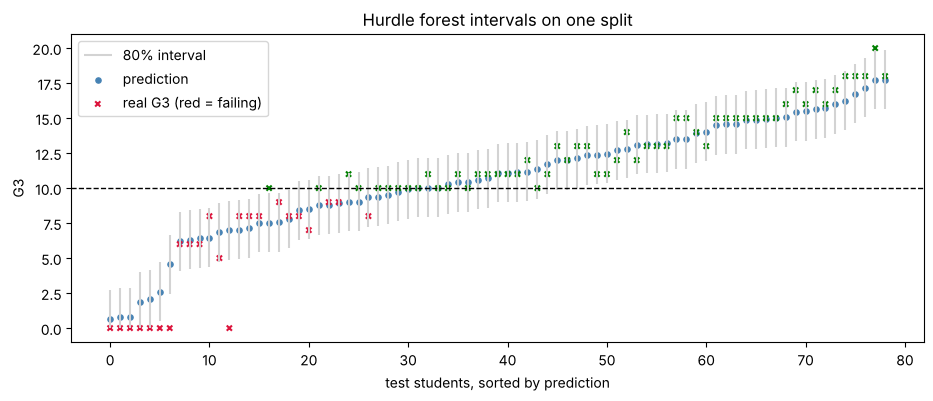

In [ ]:
test_predictions, lower, upper = first_saved['Hurdle forest']
test_grades = math.loc[first_test_index, 'G3'].values
order = np.argsort(test_predictions)
positions = np.arange(len(order))

plt.figure(figsize=(11, 4))
plt.vlines(positions, np.clip(lower[order], 0, 20), np.clip(upper[order], 0, 20), color='lightgray', label='80% interval')
plt.scatter(positions, test_predictions[order], color='steelblue', s=14, label='prediction')
colors = np.where(test_grades[order] < pass_mark, 'crimson', 'green')
plt.scatter(positions, test_grades[order], color=colors, s=14, marker='x', label='real G3 (red = failing)')
plt.axhline(pass_mark, color='black', linestyle='--', linewidth=1)
plt.xlabel('test students, sorted by prediction')
plt.ylabel('G3')
plt.title('Hurdle forest intervals on one split')
plt.legend()
plt.show()

One split of the hurdle forest, with the test students sorted by prediction. The students on the far left have predictions near 0 to 3, and almost all of them are real zeros (red crosses at 0), so the zero part is doing its job there. The red crosses (failing students) mostly sit below the dashed line at 10 and inside their grey ranges, and the green crosses close to the line are passing students whose range dips below 10, so they get flagged by mistake. The one red cross at 0 near the left is a real zero that was predicted around 7, and it is far outside its range. This is the type of student that causes the low coverage on zeros in the table.

## Part 2: Does the Portuguese prior help when there is little math data?

This is where a prior should matter most, so I shrink the math training set. I remove G2 here, because with G2 the model already knows almost everything and there is little left for a prior to add. For each training size (20, 40, 80, 160, 300 math students) I train a ridge from scratch and a ridge with the Portuguese prior, and test on the same held out math students (20% of the data, stratified on zero). Each size is repeated 30 times with different random students. I also measure two reference points that use no math students at all: the Portuguese prior by itself, and predicting the average math grade.

In [ ]:
math_X_no_G2 = make_features(math, use_G2=False)
port_X_no_G2 = make_features(port_clean, use_G2=False)
sizes = [20, 40, 80, 160, 300]
repeats = 30
curve_rows = []

for seed in range(repeats):
    is_zero = math['G3'] == 0
    pool_index, test_index = train_test_split(math.index, test_size=0.2, stratify=is_zero, random_state=seed)
    test_grades = math.loc[test_index, 'G3']
    rng = np.random.RandomState(seed)
    for size in sizes:
        train_index = rng.choice(pool_index, size=size, replace=False)
        train_grades = math.loc[train_index, 'G3']
        for name, model in [('Ridge from scratch', RidgeModel()),
                            ('Ridge + Portuguese prior', PriorRidgeModel(port_X_no_G2, port_clean['G3']))]:
            model.fit(math_X_no_G2.loc[train_index], train_grades)
            predictions = model.predict(math_X_no_G2.loc[test_index])
            curve_rows.append({'seed': seed, 'size': size, 'model': name,
                               'RMSE': np.sqrt(np.mean((test_grades - predictions) ** 2))})
    prior_only = make_ridge(port_X_no_G2).fit(port_X_no_G2, port_clean['G3'])
    curve_rows.append({'seed': seed, 'size': 0, 'model': 'Portuguese prior only',
                       'RMSE': np.sqrt(np.mean((test_grades - prior_only.predict(math_X_no_G2.loc[test_index])) ** 2))})
    curve_rows.append({'seed': seed, 'size': 0, 'model': 'Predict the math mean',
                       'RMSE': np.sqrt(np.mean((test_grades - math.loc[pool_index, 'G3'].mean()) ** 2))})

curve = pd.DataFrame(curve_rows)
curve_table = curve[curve['size'] > 0].pivot_table(index='size', columns='model', values='RMSE')
curve_table['gain'] = curve_table['Ridge from scratch'] - curve_table['Ridge + Portuguese prior']
print(curve_table.round(3))
print()
print(curve[curve['size'] == 0].groupby('model')['RMSE'].mean().round(3))

model  Ridge + Portuguese prior  Ridge from scratch   gain
size                                                      
20                        3.009               3.868  0.858
40                        2.956               3.369  0.413
80                        2.844               3.081  0.236
160                       2.777               2.888  0.110
300                       2.727               2.761  0.033

model
Portuguese prior only    3.196
Predict the math mean    4.630
Name: RMSE, dtype: float64


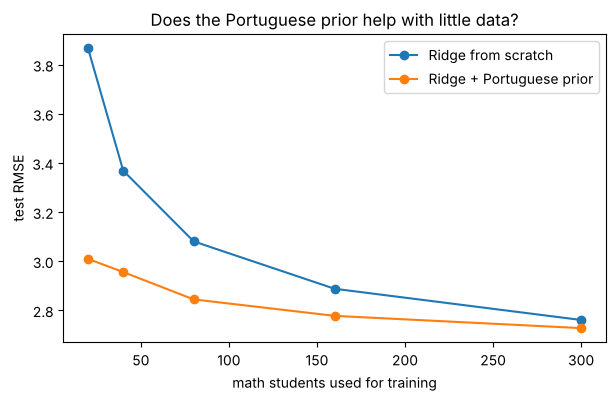

In [ ]:
plt.figure(figsize=(7, 4))
for name in ['Ridge from scratch', 'Ridge + Portuguese prior']:
    mean_curve = curve[(curve['model'] == name)].groupby('size')['RMSE'].mean()
    plt.plot(mean_curve.index, mean_curve.values, marker='o', label=name)
plt.xlabel('math students used for training')
plt.ylabel('test RMSE')
plt.title('Does the Portuguese prior help with little data?')
plt.legend()
plt.show()

The prior helps most when there is little data, and the help fades as the math training set grows: with 20 math students the RMSE is 3.009 with the prior vs 3.868 from scratch (a gain of 0.858), then 0.413 at 40 students, 0.236 at 80, 0.110 at 160, and 0.033 at 300 (2.727 vs 2.761). With no math students at all, the Portuguese model alone gets 3.196, which is much better than predicting the math average (4.630) and better than a ridge trained from scratch on 20 or 40 math students (3.868 and 3.369). From scratch only catches up to it at around 80 students (3.081). The errors here are higher than in Part 1 because G2 is removed. One thing to keep in mind is that this only shows the prior helping a ridge model on this one pair of courses, and the 275 Portuguese students are chosen by an approximate match, so I would treat the exact gain numbers as rough.